# OCR & LLM vs VLM — 같은 문서, 다른 파이프라인

- 방법 1: `pytesseract`(OCR) → 텍스트 → 텍스트 LLM(`gemma3:4b`) → JSON
- 방법 2: VLM(`qwen3-vl:4b`)이 이미지를 직접 보고 JSON 생성

참고 자료: [OCR+LLM vs VLM 영수증 처리 속도 비교](https://scv1218.tistory.com/154)

## 준비

이번 노트북은 `pytesseract`(OCR 엔진)와 텍스트 전용 LLM `gemma3:4b`를 추가로 사용합니다.

```bash
ollama pull gemma3:4b
```

Tesseract 엔진이 시스템에 설치되어 있지 않다면 [설치 링크](https://github.com/UB-Mannheim/tesseract/wiki)를
참고하세요. 설치가 안 되어 있어도 예시 텍스트로 자동 대체되어 실습은 계속 진행됩니다.

**한국어 인식이 안 될 때 (Windows):** 이 노트북은 `lang="kor+eng"`로 한국어 OCR을 시도합니다.
Windows용 설치 파일(`tesseract-ocr-w64-setup-*.exe`)은 기본값으로는 영어(`eng`)만 설치하므로,
설치 마법사 중간의 **"Additional language data" 체크박스 목록에서 Korean을 반드시 체크**해야 합니다.


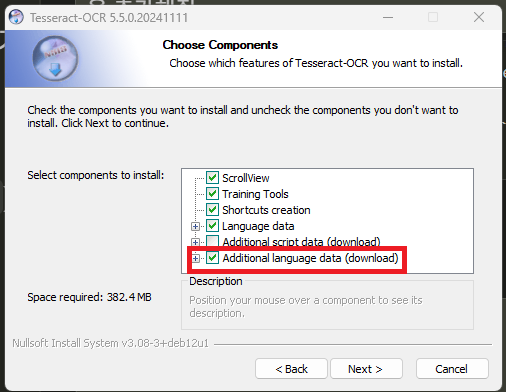

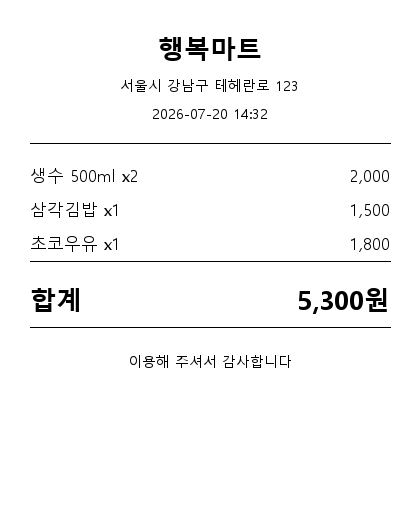

In [1]:
import json
import statistics
import time

import ollama
import pytesseract
import matplotlib.pyplot as plt
import koreanize_matplotlib  # noqa: F401

from vlm_utils import ask_json, show

# Windows: pytesseract는 tesseract.exe가 PATH에 있어야 동작합니다.
# 설치했는데도 못 찾는다면(특히 한국어 팩까지 설치했는데 계속 실패한다면) 아래처럼 경로를 직접 지정하세요.
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

RECEIPT = "data/receipt.png"
TABLE = "data/table.png"

VLM_MODEL = "qwen3-vl:4b"
TEXT_LLM_MODEL = "gemma3:4b"

show(RECEIPT)

## 1. OCR로 텍스트만 뽑아보기

OCR은 이미지 속 문자를 읽어내기만 할 뿐, "이게 상호명인지 가격인지" 같은 구조는 전혀 모릅니다.
결과가 얼마나 정리되지 않은 "날것"인지 먼저 눈으로 확인합니다.

In [2]:
FALLBACK_OCR_TEXT = """행복마트
서울시 강남구 테헤란로 123
2026-07-20 14:32

생수 500ml x2         2,000
삼각김밥 x1            1,500
초코우유 x1            1,800

합계                  5,300원
이용해 주셔서 감사합니다"""


def ocr_extract_text(image_path, fallback=FALLBACK_OCR_TEXT):
    try:
        return pytesseract.image_to_string(image_path, lang="kor+eng")
    except Exception as e:
        print(f"OCR extraction failed ({e}), using fallback text.")
        return fallback


receipt_text = ocr_extract_text(RECEIPT)
print(receipt_text)

행복마트
서울시 강남구 테헤란로 123
2026-07-20 14:32

생수 500m! x2                         2,000
삼각김밥 x1                                 1,500
초코우유 01                                 1.800
sl                                              으

합계                               5,300원

이릉해 주셔서 감사합니다



## 2. OCR 텍스트 → LLM으로 구조화 (2단계 파이프라인)

방금 뽑은 텍스트를 텍스트 전용 LLM에 넣어 JSON으로 정리시킵니다.
이미지 없이 **텍스트만** 입력한다는 점이 VLM 방식과 다릅니다.

In [3]:
RECEIPT_SCHEMA_PROMPT = """아래 영수증 텍스트를 이 JSON 스키마로만 정리해줘.
{{
  "store": "string",
  "date": "YYYY-MM-DD",
  "items": [{{"name": "string", "qty": "number", "price": "number"}}],
  "total": "number"
}}

영수증 텍스트:
{text}
"""


def text_llm_json(text, schema_prompt_template, model=TEXT_LLM_MODEL):
    response = ollama.chat(
        model=model,
        messages=[{"role": "user", "content": schema_prompt_template.format(text=text)}],
        format="json",
    )
    return json.loads(response["message"]["content"])


ocr_llm_result = text_llm_json(receipt_text, RECEIPT_SCHEMA_PROMPT)
print(ocr_llm_result)

{'store': '행복마트', 'date': '2026-07-20', 'items': [{'name': '생수 500m!', 'qty': 2, 'price': 2000}, {'name': '삼각김밥', 'qty': 1, 'price': 1500}, {'name': '초코우유 01', 'qty': 1, 'price': 1800}], 'total': 5300}


## 3. VLM 직접 추출
이미지를 그대로 VLM에 넣어 JSON을 바로 받습니다.   
스키마는 OCR+LLM 파이프라인과 동일하게 맞춰서 공정하게 비교합니다.

In [4]:
VLM_SCHEMA_PROMPT = """아래 JSON 스키마로만 답해.
{
  "store": "string",
  "date": "YYYY-MM-DD",
  "items": [{"name": "string", "qty": "number", "price": "number"}],
  "total": "number"
}
"""

vlm_result = ask_json(RECEIPT, VLM_SCHEMA_PROMPT, model=VLM_MODEL)
print(vlm_result)

{'store': '행복마트', 'date': '2026-07-20', 'items': [{'name': '생수 500ml', 'qty': 2, 'price': 1000}, {'name': '삼각김밥', 'qty': 1, 'price': 1500}, {'name': '초코우유', 'qty': 1, 'price': 1800}], 'total': 5300}


## 4. 결과 비교

두 결과를 나란히 놓고 필드가 정확히 맞는지 확인합니다.    
(정답: 상호=행복마트, 날짜=2026-07-20, 합계=5,300원)

In [5]:
print("OCR+LLM:", json.dumps(ocr_llm_result, ensure_ascii=False, indent=2))
print()
print("VLM    :", json.dumps(vlm_result, ensure_ascii=False, indent=2))

OCR+LLM: {
  "store": "행복마트",
  "date": "2026-07-20",
  "items": [
    {
      "name": "생수 500m!",
      "qty": 2,
      "price": 2000
    },
    {
      "name": "삼각김밥",
      "qty": 1,
      "price": 1500
    },
    {
      "name": "초코우유 01",
      "qty": 1,
      "price": 1800
    }
  ],
  "total": 5300
}

VLM    : {
  "store": "행복마트",
  "date": "2026-07-20",
  "items": [
    {
      "name": "생수 500ml",
      "qty": 2,
      "price": 1000
    },
    {
      "name": "삼각김밥",
      "qty": 1,
      "price": 1500
    },
    {
      "name": "초코우유",
      "qty": 1,
      "price": 1800
    }
  ],
  "total": 5300
}


## 5. 벤치마킹 — 반복 측정으로 신뢰성 있게 비교하기

1회 측정은 우연일 수 있습니다. warm-up으로 모델을 먼저 한 번 예열한 뒤,       
여러 번 반복 실행해서 평균과 표준편차를 비교합니다.

In [6]:
def run_ocr_llm_pipeline(image_path, schema_prompt_template, fallback=FALLBACK_OCR_TEXT):
    text = ocr_extract_text(image_path, fallback=fallback)
    return text_llm_json(text, schema_prompt_template)


def run_vlm_pipeline(image_path, schema_prompt):
    return ask_json(image_path, schema_prompt, model=VLM_MODEL)


def benchmark(fn, *args, n=5, warmup=1):
    for _ in range(warmup):
        fn(*args)
    times = []
    for _ in range(n):
        start = time.time()
        fn(*args)
        times.append(time.time() - start)
    return times


ocr_llm_times = benchmark(run_ocr_llm_pipeline, RECEIPT, RECEIPT_SCHEMA_PROMPT)
vlm_times = benchmark(run_vlm_pipeline, RECEIPT, VLM_SCHEMA_PROMPT)

print("OCR+LLM (초):", [f"{t:.2f}" for t in ocr_llm_times])
print("VLM     (초):", [f"{t:.2f}" for t in vlm_times])

OCR+LLM (초): ['14.25', '16.68', '14.41', '16.69', '14.14']
VLM     (초): ['17.11', '17.69', '17.96', '17.18', '17.13']


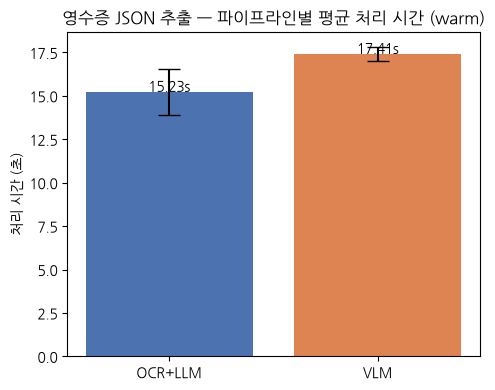

In [7]:
labels = ["OCR+LLM", "VLM"]
means = [statistics.mean(ocr_llm_times), statistics.mean(vlm_times)]
stds = [statistics.stdev(ocr_llm_times), statistics.stdev(vlm_times)]

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(labels, means, yerr=stds, capsize=8, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("처리 시간 (초)")
ax.set_title("영수증 JSON 추출 — 파이프라인별 평균 처리 시간 (warm)")

for i, m in enumerate(means):
    ax.text(i, m + 0.05, f"{m:.2f}s", ha="center")
fig.tight_layout()
plt.show()

## 6. 확장 실험 — 레이아웃이 복잡한 문서에서도 같은 결론일까?

영수증은 텍스트가 위→아래로 나열된 정형화된 문서라 OCR이 유리했을 수 있습니다.
3번 노트북에서 다룬 표(`table.png`)처럼 **행-열 관계**가 중요한 문서에서도
같은 파이프라인을 실행해서 결과를 비교해봅니다.

먼저 예측해보세요: 표 이미지에서도 OCR+LLM이 더 빠르고 정확할까요?

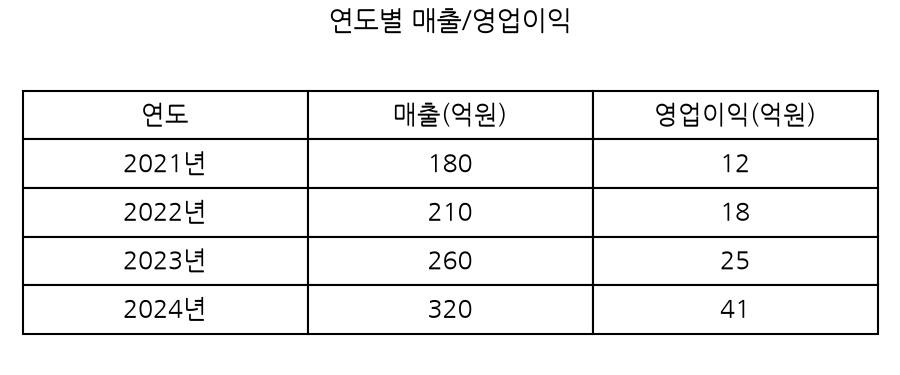

OCR+LLM: {'rows': [{'year': '2021년', 'revenue': 180, 'profit': 12}, {'year': '2022년', 'revenue': 210, 'profit': 18}, {'year': '2023년', 'revenue': 260, 'profit': 25}, {'year': '2024년', 'revenue': 320, 'profit': 41}]}
VLM    : {'rows': [{'year': '2021년', 'revenue': 180, 'profit': 12}, {'year': '2022년', 'revenue': 210, 'profit': 18}, {'year': '2023년', 'revenue': 260, 'profit': 25}, {'year': '2024년', 'revenue': 320, 'profit': 41}]}

정답: 2021~2024년 매출 180/210/260/320, 영업이익 12/18/25/41 (억원)


In [8]:
show(TABLE)

FALLBACK_TABLE_OCR_TEXT = """연도별 매출/영업이익
연도 매출(억원) 영업이익(억원)
2021년 180 12
2022년 210 18
2023년 260 25
2024년 320 41"""

TABLE_SCHEMA_PROMPT_TEMPLATE = """아래는 표 이미지를 OCR로 읽은 텍스트야. 이 JSON 스키마로만 정리해줘.
{{
  "rows": [{{"year": "string", "revenue": "number", "profit": "number"}}]
}}

표 텍스트:
{text}
"""

TABLE_VLM_PROMPT = """이 표 이미지를 아래 JSON 스키마로만 정리해줘.
{
  "rows": [{"year": "string", "revenue": "number", "profit": "number"}]
}
"""

table_ocr_llm_result = run_ocr_llm_pipeline(
    TABLE, TABLE_SCHEMA_PROMPT_TEMPLATE, fallback=FALLBACK_TABLE_OCR_TEXT
)
table_vlm_result = run_vlm_pipeline(TABLE, TABLE_VLM_PROMPT)

print("OCR+LLM:", table_ocr_llm_result)
print("VLM    :", table_vlm_result)
print("\n정답: 2021~2024년 매출 180/210/260/320, 영업이익 12/18/25/41 (억원)")

## 7. 정리 — 언제 무엇을 쓸까

| 상황 | 추천 |
|---|---|
| 정형화·반복적인 문서 (영수증, 정형 양식) | OCR+LLM — 속도 우위 |
| 레이아웃이 복잡한 문서 (표, 계약서, 손글씨) | VLM — 구조 이해력 우위 |
| 확신이 없을 때 | 오늘처럼 직접 벤치마킹 |

**핵심은 속도만으로 파이프라인을 고르지 않는 것입니다.** 정확도까지 함께 측정해야
실제 서비스에 맞는 선택을 할 수 있습니다.